In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

words = open('names.txt', 'r').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [2]:
chars = sorted(list(set(''.join(words))))
stoi = {s : i + 1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
print(itos)


{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [109]:
block_size = 3
X, Y = [], []
for w in words:

    context = [8] * block_size
    for ch in w + '.':
        ix = stoi[ch]
        X.append(context)
        Y.append(ix)
        context = context[1:] + [ix]

X = torch.tensor(X)
Y = torch.tensor(Y)

In [111]:
def build_dataset(words):
    block_size = 3
    X, Y = [], []
    for w in words:

        context = [8] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            context = context[1:] + [ix]

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))
Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [39]:
C = torch.randn((27, 2))

In [40]:
emb = C[X]

In [41]:
W1 = torch.randn((6, 100))
b1 = torch.randn(100)


In [42]:
h = torch.tanh(emb.view(-1, 6) @ W1 + b1)
h


tensor([[ 0.1485, -0.9971,  0.3467,  ...,  0.8117, -0.2813,  0.9986],
        [ 0.0579, -0.9670,  0.6687,  ...,  0.8100,  0.8951,  0.9513],
        [ 0.9846, -0.9962,  0.2931,  ...,  0.2440, -0.8019,  0.7289],
        ...,
        [ 1.0000,  0.8557, -0.8193,  ...,  0.8614,  0.9986, -1.0000],
        [ 0.9963,  0.9196,  0.9799,  ..., -0.5448,  0.9910, -1.0000],
        [ 0.9979,  0.8858, -0.8584,  ...,  0.9253,  1.0000, -1.0000]])

In [43]:
W2 = torch.randn((100, 27))
b2 = torch.randn(27)

In [44]:
logits = h @ W2 + b2

In [45]:
counts = logits.exp()
prob = counts / counts.sum(1, keepdims=True)


In [47]:
loss = -prob[torch.arange(len(Y)), Y].log().mean()

In [112]:
Xtr.shape, Ytr.shape # dataset

(torch.Size([182625, 3]), torch.Size([182625]))

In [132]:
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27, 10), generator=g)
W1 = torch.randn((30, 200), generator=g)
b1 = torch.randn(200, generator=g)
W2 = torch.randn((200, 27), generator=g)
b2 - torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

In [133]:
sum(p.nelement() for p in parameters) # total number of parameters

11897

In [134]:
for p in parameters:
    p.requires_grad = True

In [102]:
lre = torch.linspace(-3, 0, 1000)
lrs = 10**lre

In [135]:
lri = []
lossi = []
stepi = []

In [140]:
for i in range(50000):
    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (32,))

    # forward pass
    emb = C[X[ix]] # (32, 3, 2)
    h = torch.tanh(emb.view(-1, 30) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Ytr[ix])


    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    lr = 0.01
    for p in parameters:
        p.data += -lr * p.grad

    # track stats
    stepi.append(i)
    lossi.append(loss.log10().item())


#print(loss.item())

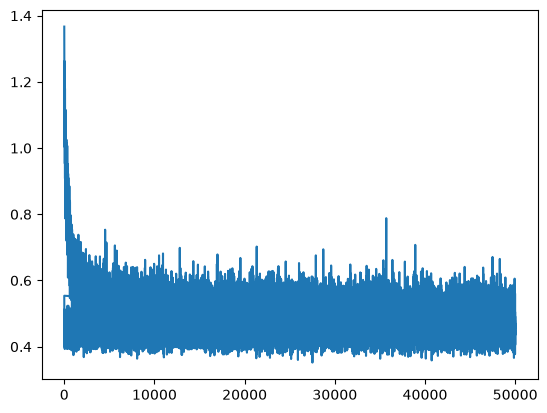

In [141]:
plt.plot(stepi, lossi)

In [143]:
emb = C[Xdev] # (32, 3, 2)
h = torch.tanh(emb.view(-1, 30) @ W1 + b1) 
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Ydev)
loss.item()

2.8416054248809814

In [ ]:
# training split, dev/validation split, test split
# 80%, 10%, 10%